# Critically sampled cosine-modulated filter bank

This exercise illustrates **analysis filtering → downsampling by the number of bands → upsampling → synthesis filtering**. With `M` bands and decimation by `M`, the total number of subband samples per second is approximately the same as the input sample rate: this is **critical sampling**.

**Important:** The cosine-modulated filters constructed below form a *demonstration filter bank*, **not a perfect-reconstruction (PR) bank**. Decimation aliases spectral components, and these particular synthesis filters do not guarantee cancellation of that aliasing. A reconstructed signal can therefore have noticeable errors even when the code is correct.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from pathlib import Path
from scipy import signal
from scipy.io import wavfile

EPS = np.finfo(float).tiny


def read_sound(filename):
    """Load a WAV file as mono float audio; preserve the file's true sample rate."""
    fs, audio = wavfile.read(filename)
    if np.issubdtype(audio.dtype, np.integer):
        # int16, int32 and uint8 PCM need different zero-point/scales.
        if audio.dtype.kind == 'u':
            audio = (audio.astype(np.float64) - 128.0) / 128.0
        else:
            audio = audio.astype(np.float64) / float(2 ** (audio.dtype.itemsize * 8 - 1))
    else:
        audio = audio.astype(np.float64)
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    return audio, fs


def prototype_filter(num_taps, num_bands):
    """Windowed low-pass prototype (cutoff expressed relative to Nyquist)."""
    if num_taps < 3 or num_taps % 2 != 1:
        raise ValueError('Use an odd number of taps >= 3 for integer delay.')
    return signal.firwin(num_taps, 1.0 / (2 * num_bands), window='hamming')


def modulate_filter(h, num_bands, band):
    """Shift the low-pass prototype to the centre of cosine-modulated band k."""
    n = np.arange(len(h))
    centre = (len(h) - 1) / 2
    return 2 * h * np.cos(np.pi * (2 * band + 1) * (n - centre) / (2 * num_bands))


def get_filters(num_bands, num_taps):
    h = prototype_filter(num_taps, num_bands)
    return np.array([modulate_filter(h, num_bands, k) for k in range(num_bands)])


def analysis_filter_bank(x, filters, num_bands):
    """Convolve with each analysis filter and decimate every M samples.

    Full convolution preserves the filter tails; all subbands have the same size.
    This implementation is direct filtering, *not* a polyphase optimization.
    """
    return np.array([signal.fftconvolve(x, hk, mode='full')[::num_bands]
                     for hk in filters])


def synthesis_filter_bank(subbands, filters, num_bands):
    """Upsample by M, filter each branch, and sum the branch outputs.

    Zero insertion by itself does not reconstruct missing samples; synthesis
    filters interpolate each branch. These filters are illustrative, not PR.
    """
    out_length = num_bands * subbands.shape[1] + filters.shape[1] - 1
    output = np.zeros(out_length)
    for band, hk in enumerate(filters):
        upsampled = np.zeros(num_bands * subbands.shape[1])
        upsampled[::num_bands] = subbands[band]
        branch = signal.fftconvolve(upsampled, hk, mode='full')
        output[:len(branch)] += branch
    return output


def play_at_common_gain(*sounds, fs):
    """Play without independent auto-normalization (otherwise gains are hidden)."""
    peak = max(np.max(np.abs(s)) for s in sounds)
    gain = min(1.0, 0.95 / peak) if peak else 1.0
    for sound in sounds:
        ipd.display(ipd.Audio(sound * gain, rate=fs, normalize=False))


## 1. Choose an audio signal and design the filters

If the course trumpet file is not present, generate a reproducible harmonic test signal. The **actual sampling rate** is used throughout.

For a symmetric FIR filter with `N` taps, the analysis or synthesis filter delay is `(N-1)/2` samples. Choosing odd `N` makes each delay an integer; the **combined nominal delay `N-1` is an integer for either parity**. This simple bank does not guarantee perfect reconstruction.

Loaded ../sounds/487465-trumpet.wav: 112076 samples, 44100 Hz
16 bands, nominal subband rate = 2756.2 samples/s


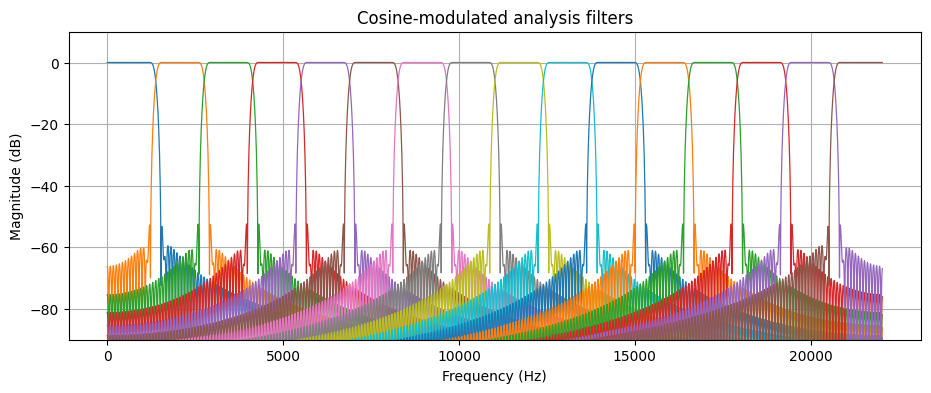

In [2]:
M = 16                 # Number of subbands (also the downsampling factor)
N = 513                # Odd FIR length; longer filters give sharper transitions
path = Path('../sounds/487465-trumpet.wav')

if path.exists():
    x, fs = read_sound(path)
    print(f'Loaded {path}: {len(x)} samples, {fs} Hz')
else:
    fs = 44100
    t = np.arange(fs) / fs
    x = 0.35 * np.sin(2 * np.pi * 220 * t)
    x += 0.20 * np.sin(2 * np.pi * 440 * t)
    x += 0.12 * np.sin(2 * np.pi * 880 * t)
    print('WAV file not found: using a synthetic harmonic test signal.')

filters = get_filters(M, N)
print(f'{M} bands, nominal subband rate = {fs/M:.1f} samples/s')

# Display the response of each analysis filter.
plt.figure(figsize=(11, 4))
for k in range(M):
    freq, response = signal.freqz(filters[k], worN=2048, fs=fs)
    plt.plot(freq, 20*np.log10(np.maximum(np.abs(response), 1e-8)), lw=0.9)
plt.title('Cosine-modulated analysis filters')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim(-90, 10)
plt.grid(True)
plt.show()

## 2. What makes this filter bank **critically sampled**?

The input has `fs` samples per second. We split it into `M` analysis-filter outputs, **then keep only one out of every `M` samples in each branch**. As a result, each subband has a sampling rate of `fs/M` and all `M` subbands together carry `M × (fs/M) = fs` samples per second. This is the **critical-sampling rate**: no sample-rate redundancy across channels.

```text
                                  ANALYSIS                               SYNTHESIS
                               filter    ↓M                         ↑M    filter
                        ┌──► h₀[n] ──► ↓M ──► b₀[m] ─────────────► ↑M ──► g₀[n] ──┐
                        │                                                             │
input x[n] ─────────────┼──► h₁[n] ──► ↓M ──► b₁[m] ─────────────► ↑M ──► g₁[n] ──┼──► Σ ──► y[n]
                        │                                                             │
                        └──► ...       ...                 ...           ...       ──┘
```

- **Downsampling (`↓M`, decimation)** is implemented by `filtered[::M]` inside `analysis_filter_bank()`; index `m` in a subband corresponds to every `M`-th sample of the filtered signal.
- **Upsampling (`↑M`, zero insertion)** is implemented by `upsampled[::M] = subbands[band]` inside `synthesis_filter_bank()`. It inserts `M-1` zeros between subband samples; the synthesis filter then interpolates.
- **Important:** critical sampling is a *rate/count property*, **not a perfect-reconstruction guarantee**. Downsampling can introduce aliasing; the particular analysis/synthesis filters used here do not guarantee alias cancellation. Also, convolution produces boundary tails, so stored finite arrays can have slightly more samples than the ideal steady-state rate suggests.

Input:       112,076 samples at 44,100 Hz
Filtered:    112,588 samples (includes convolution tails)
Decimated:   7,037 samples at 2,756.25 samples/s
Zero-insert: 112,592 samples at 44,100 Hz
One-branch interpolation output: 113,104 samples


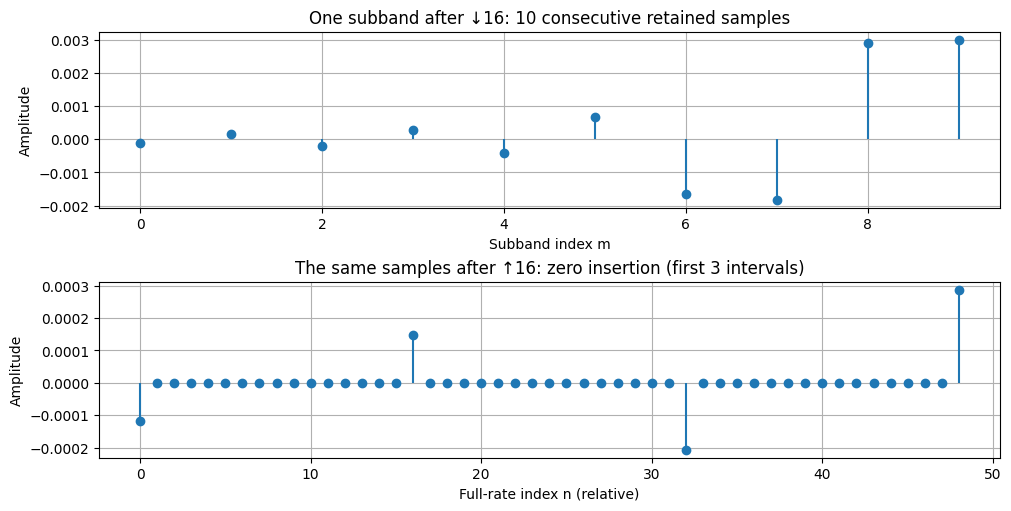

In [3]:
# Explicitly follow ONE analysis branch: filtering -> decimation.
# The stored subband has roughly 1/M as many samples as the filtered signal.
k = 0
filtered_k = signal.fftconvolve(x, filters[k], mode='full')
decimated_k = filtered_k[::M]         # ↓M: keep samples 0, M, 2M, ...

# One synthesis branch: insert M-1 zeros, then filter to interpolate.
upsampled_k = np.zeros(M * len(decimated_k))
upsampled_k[::M] = decimated_k        # ↑M: zeros at all other positions
interpolated_k = signal.fftconvolve(upsampled_k, filters[k], mode='full')

print(f'Input:       {len(x):,} samples at {fs:,.0f} Hz')
print(f'Filtered:    {len(filtered_k):,} samples (includes convolution tails)')
print(f'Decimated:   {len(decimated_k):,} samples at {fs/M:,.2f} samples/s')
print(f'Zero-insert: {len(upsampled_k):,} samples at {fs:,.0f} Hz')
print(f'One-branch interpolation output: {len(interpolated_k):,} samples')

# Display a small interior interval of subband values and where they are placed
# on the full-rate time grid by upsampling. No invented samples are recovered
# at this stage: the extra entries are exactly zero.
start = min(10, max(0, len(decimated_k)-12))
selected = decimated_k[start:start+10]
placed = np.zeros(M * len(selected))
placed[::M] = selected
fig, axes = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
axes[0].stem(np.arange(len(selected)), selected, basefmt=' ')
axes[0].set(title=f'One subband after ↓{M}: 10 consecutive retained samples', xlabel='Subband index m', ylabel='Amplitude')
axes[1].stem(np.arange(min(len(placed), 3*M+1)), placed[:3*M+1], basefmt=' ')
axes[1].set(title=f'The same samples after ↑{M}: zero insertion (first 3 intervals)', xlabel='Full-rate index n (relative)', ylabel='Amplitude')
for a in axes: a.grid(True)
plt.show()

### Counting samples: with and without critical sampling

If `M = 16` and the input is sampled at 44,100 Hz, then the rate in **each** subband after `↓16` is 2,756.25 samples/s. Across **all 16 subbands**, the total is 44,100 samples/s, exactly one input sample rate. In contrast, keeping every sample in all 16 filtered outputs would give `16 × 44,100 = 705,600` samples/s: an **oversampled/redundant** analysis representation.

This is a count of sample values, **not a claim that the bank preserves all information**: that also depends on the filters and reconstruction. In finite arrays, convolution tails and rounding cause small count differences.

In [4]:
# Verify the critical-sampling rate using the actual subband arrays.
# Each full-rate filtered branch contains len(x) + N - 1 samples due to tails.
subbands = analysis_filter_bank(x, filters, M)
input_rate = fs
fullrate_bank_rate = M * fs
critically_sampled_rate = M * (fs/M)

print(f'M = {M} channels, downsampling factor D = {M}')
print(f'Input samples: {len(x):,}; one subband length: {subbands.shape[1]:,}')
print(f'Input sample rate:                    {input_rate:,.2f} samples/s')
print(f'All channels WITHOUT downsampling:   {fullrate_bank_rate:,.2f} samples/s')
print(f'All channels WITH downsampling by M: {critically_sampled_rate:,.2f} samples/s')
print(f'Rates ratio: {critically_sampled_rate/input_rate:.1f}× (critical sampling)')
print(f'Finite stored subband samples: {subbands.size:,} '
      f'(vs. input {len(x):,}; filter tails explain the difference)')

assert subbands.shape[0] == M
assert np.isclose(critically_sampled_rate, input_rate)

M = 16 channels, downsampling factor D = 16
Input samples: 112,076; one subband length: 7,037
Input sample rate:                    44,100.00 samples/s
All channels WITHOUT downsampling:   705,600.00 samples/s
All channels WITH downsampling by M: 44,100.00 samples/s
Rates ratio: 1.0× (critical sampling)
Finite stored subband samples: 112,592 (vs. input 112,076; filter tails explain the difference)


## 3. Reconstruction and listening

Every subband is **upsampled by `M` and passed through a synthesis filter**, and all synthesis outputs are summed. Here, `↑M` does *not* simply replicate sample values: it inserts zeros, and the synthesis filter fills in intermediate values through filtering.

Each symmetric FIR introduces nominal delay `(N-1)/2`. With the same length for analysis and synthesis, the nominal delay is `N-1` samples, which we compensate when plotting and comparing audio. This bank is **not** a guaranteed perfect-reconstruction filter bank: gain, aliasing and other distortion may remain even after alignment.

Subbands shape: (16, 7037)
Nominal delay: 512 samples (11.61 ms)
Estimated overall gain correction: 16.958
Relative RMS reconstruction error after delay/gain alignment: 20.530%
A nonzero error is expected: this is NOT a perfect-reconstruction bank.


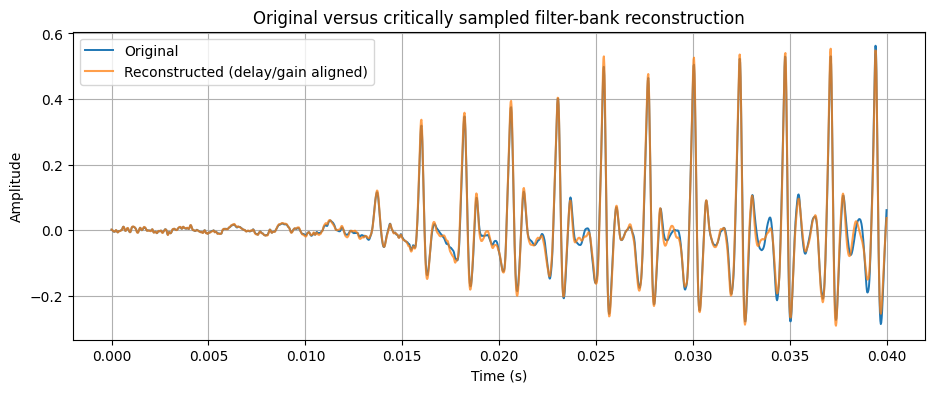

Original:
Reconstructed (aligned and gain corrected):


In [5]:
y_full = synthesis_filter_bank(subbands, filters, M)

# Compare the same time positions. Never compare the unaligned output directly:
# the apparent error would otherwise include the filter-bank delay.
delay = N - 1
y = y_full[delay:delay + len(x)]
assert len(y) == len(x)

# These filters have a non-unit end-to-end gain. Estimate a single scalar gain
# for diagnostic listening; this DOES NOT remove aliasing or frequency distortion.
gain_fit = np.dot(x, y) / max(np.dot(y, y), EPS)
y_gain_corrected = gain_fit * y

rms = lambda a: np.sqrt(np.mean(a**2))
relative_error = rms(x - y_gain_corrected) / max(rms(x), EPS)
print('Subbands shape:', subbands.shape)
print(f'Nominal delay: {delay} samples ({1000*delay/fs:.2f} ms)')
print(f'Estimated overall gain correction: {gain_fit:.3f}')
print(f'Relative RMS reconstruction error after delay/gain alignment: {relative_error:.3%}')
print('A nonzero error is expected: this is NOT a perfect-reconstruction bank.')

# Plot a short interval so waveform differences are visible.
plot_length = min(len(x), int(0.04 * fs))
time = np.arange(plot_length) / fs
plt.figure(figsize=(11, 4))
plt.plot(time, x[:plot_length], label='Original', lw=1.4)
plt.plot(time, y_gain_corrected[:plot_length], label='Reconstructed (delay/gain aligned)', alpha=0.75)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Original versus critically sampled filter-bank reconstruction')
plt.legend()
plt.grid(True)
plt.show()

print('Original:')
print('Reconstructed (aligned and gain corrected):')
# Both are played with the SAME gain, preserving the audible difference.
play_at_common_gain(x, y_gain_corrected, fs=fs)

## 4. Listening and interpretation

- **Critical sampling:** with `M` bands each reduced by a factor of `M`, the aggregate sample rate is approximately the original rate, not `M` times larger.
- **Aliasing:** after decimation, frequency components fold into each subband's reduced Nyquist interval. A properly designed PR bank uses its analysis/synthesis structure to cancel these aliases after recombination.
- **Filter design matters:** the present cosine-modulated Hamming-windowed filters do not satisfy the complete alias-cancellation and distortion-transfer conditions for perfect reconstruction.
- **Amplitude matters:** notebook playback should not independently normalize the original and reconstruction, because doing so hides gain differences.
- **Implementation note:** the code computes each filtering branch directly. A *polyphase implementation* can be much more efficient, but critical sampling does not automatically imply polyphase processing.

### Try it
Change `M` and `N`, rerun the notebook, and compare the filter responses, delay and relative RMS reconstruction error. A longer FIR generally improves frequency selectivity but **does not guarantee perfect reconstruction**.
